<a href="https://colab.research.google.com/github/Mehdi-mo/nuclei-segmentation-unet/blob/main/nuclei_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

ROOT  = "nuclei_data/Nuclei/Nuclei"
TRAIN = f"{ROOT}/stage_1_train"

In [3]:
!kaggle datasets download -d gangadhar/nuclei-segmentation-in-microscope-cell-images
!unzip -q nuclei-segmentation-in-microscope-cell-images.zip -d nuclei_data

Dataset URL: https://www.kaggle.com/datasets/gangadhar/nuclei-segmentation-in-microscope-cell-images
License(s): copyright-authors
100% 371M/371M [00:02<00:00, 164MB/s]



In [4]:
from google.colab import drive
drive.mount('/content/drive')
!cp nuclei-segmentation-in-microscope-cell-images.zip /content/drive/MyDrive/

Mounted at /content/drive


In [5]:
!pip install -q pycocotools
from pycocotools.coco import COCO

coco = COCO(f"{ROOT}/annotations/stage1_train.json")
print("images:", len(coco.imgs), "| nuclei:", len(coco.anns))

loading annotations into memory...
Done (t=0.13s)
creating index...
index created!
images: 664 | nuclei: 28986


In [6]:
img_id = coco.getImgIds()[0]
info   = coco.loadImgs(img_id)[0]

photo = Image.open(os.path.join(TRAIN, info["file_name"])).convert("RGB")
print(info["file_name"], photo.size)

4ca5081854df7bbcaa4934fcf34318f82733a0f8c05b942c2265eea75419d62f.jpg (320, 256)


In [7]:
ann_ids = coco.getAnnIds(imgIds=img_id)
anns    = coco.loadAnns(ann_ids)

print("nuclei in this image:", len(anns))

nuclei in this image: 37


In [8]:
mask = np.zeros((info["height"], info["width"]), dtype=np.uint8)

for ann in anns:
    one_nucleus = coco.annToMask(ann)
    mask = np.maximum(mask, one_nucleus)

print(mask.shape, mask.min(), mask.max())
print("fraction of pixels that are nucleus:", mask.mean().round(3))

(256, 320) 0 1
fraction of pixels that are nucleus: 0.085


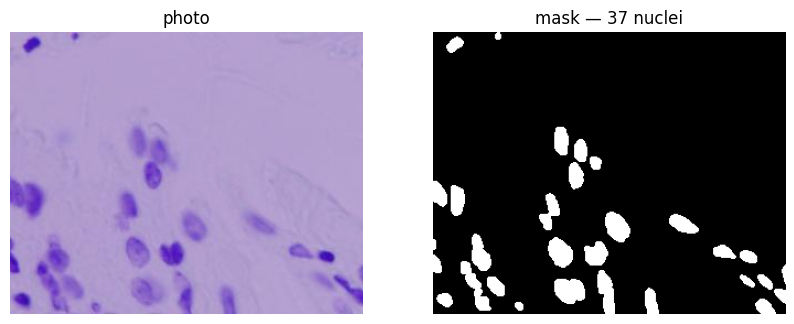

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(photo)
ax[0].set_title("photo")

ax[1].imshow(mask, cmap="gray")
ax[1].set_title(f"mask — {len(anns)} nuclei")

for a in ax:
    a.axis("off")

plt.show()

In [10]:
from tqdm.notebook import tqdm   # progress bar — tqdm is already on Colab

MASK_DIR = "nuclei_data/masks"
os.makedirs(MASK_DIR, exist_ok=True)          # create the folder if missing

all_ids = coco.getImgIds()

for img_id in tqdm(all_ids, desc="building masks"):
    info    = coco.loadImgs(img_id)[0]
    ann_ids = coco.getAnnIds(imgIds=img_id)
    anns    = coco.loadAnns(ann_ids)

    mask = np.zeros((info["height"], info["width"]), dtype=np.uint8)
    for ann in anns:
        mask = np.maximum(mask, coco.annToMask(ann))

    stem = os.path.splitext(info["file_name"])[0]   # "abc123.jpg" → "abc123"
    Image.fromarray(mask * 255).save(os.path.join(MASK_DIR, f"{stem}.png"))

print("done —", len(all_ids), "masks saved")

building masks:   0%|          | 0/664 [00:00<?, ?it/s]

done — 664 masks saved


In [13]:
from sklearn.model_selection import train_test_split

train_ids, val_ids = train_test_split(
    all_ids,
    test_size=0.2,
    random_state=42,
)

print('train:', len(train_ids), 'val:', len(val_ids))

train: 531 val: 133
